# Phase 4: baselines B0-B5, evaluation harness, canaries, week-2 gate
Development cells of Protocol D only (84 cells). No deep models, no GPU, no raw .mat files, no installs.
Writes only to `outputs/phase4` (OUT, FIG, CACHE). Resumable through per-fold prediction caches.

In [1]:
# Imports, config, helpers
import os, sys, json, time, hashlib, inspect, warnings, traceback, re
from pathlib import Path
import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.stats import skew
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

T0 = time.time()
SEED = 42; NOMINAL_AH = 1.1; TRAIN_STRIDE = 5; BOOT = 5000; N_JOBS = 10; GATE_IMPROVEMENT = 0.15

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROC = ROOT / "data/processed"; SPL = PROC / "splits"
OUT = ROOT / "outputs/phase4"; FIG = OUT / "figures"; CACHE = OUT / "cache"
SRC = ROOT / "src"; P3 = ROOT / "outputs/phase3"
for d in (OUT, FIG, CACHE):
    d.mkdir(parents=True, exist_ok=True)

CHECKS, ERRORS = [], []

def check(name, passed, detail="", level="FAIL"):
    """Record a check. A failed check is FAIL unless level='WARN'."""
    status = "PASS" if passed else level
    CHECKS.append({"name": name, "status": status, "detail": str(detail)})
    print(f"[{status}] {name}" + (f" | {detail}" if str(detail) else ""))
    return bool(passed)

def record_error(where, exc):
    msg = f"{where}: {type(exc).__name__}: {exc}"
    ERRORS.append({"where": where, "error": f"{type(exc).__name__}: {exc}",
                   "trace": traceback.format_exc()[-1500:]})
    print("[ERROR]", msg)

def wpath(p):
    """Return p only if it lies inside OUT (which contains FIG and CACHE)."""
    p = Path(p).resolve()
    assert OUT.resolve() in p.parents, f"write outside OUT refused: {p}"
    return p

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for blk in iter(lambda: fh.read(1 << 20), b""):
            h.update(blk)
    return h.hexdigest()

vm = psutil.virtual_memory()
check("available RAM >= 2 GB", vm.available >= 2 * 1024**3, f"{vm.available/1024**3:.1f} GB free; close other apps if low", "WARN")
print("ROOT:", ROOT)

c:\workstation\3RD YEAR\Battery-Health-Estimation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[PASS] available RAM >= 2 GB | 3.4 GB free; close other apps if low
ROOT: c:\workstation\3RD YEAR\Battery-Health-Estimation


In [2]:
# soh_common helpers (read-only import)
sys.path.insert(0, str(SRC))
import soh_common as sc
for nm in ["load_tables", "grid_index", "window_slice", "assert_allowed", "build_delta_q", "window_valid"]:
    f = getattr(sc, nm, None)
    print(f"{nm}{inspect.signature(f) if callable(f) else ': MISSING'}")
print("shuffle_labels_within_cell present:", callable(getattr(sc, "shuffle_labels_within_cell", None)))
print("Used here: grid_index, build_delta_q, assert_allowed. "
      "Not used: load_tables (tables read directly), window_slice, window_valid (validity is checked on finite features).")

WINDOWS = {"W310": 3.10, "W305": 3.05, "W300": 3.00, "W280": 2.80, "W240": 2.40, "WFULL": 2.00}
MINUTES = {"W310": 5.9, "W305": 8.6, "W300": 10.2, "W280": 12.4, "W240": 13.5, "WFULL": 13.9}
PHASE3B_R2 = {"W310": 0.711, "W300": 0.775, "W240": 0.917, "WFULL": 0.918}

def gi(V):
    ref = int(round((3.5 - V) / 0.0015015))
    try:
        got = int(sc.grid_index(V))
        check(f"grid_index({V}) equals round((3.5-V)/0.0015015)", got == ref, f"{got} vs {ref}", "WARN")
        return got
    except Exception as e:
        record_error(f"grid_index({V}); formula used", e)
        return ref

I_OPEN = gi(3.5)
I_CLOSE = {w: gi(v) for w, v in WINDOWS.items()}
print("I_OPEN", I_OPEN, "I_CLOSE", I_CLOSE)

load_tables(root=None, mmap=True)
grid_index(voltage)
window_slice(open_v, close_v)
assert_allowed(columns, allowlist=None, roles=('primary', 'ablation'))
build_delta_q(qdlin_row, qref, i_open, i_close, n_points=None)
window_valid(qdlin_row, i_open, i_close, max_step_ah=0.05)
shuffle_labels_within_cell present: True
Used here: grid_index, build_delta_q, assert_allowed. Not used: load_tables (tables read directly), window_slice, window_valid (validity is checked on finite features).
[PASS] grid_index(3.5) equals round((3.5-V)/0.0015015) | 0 vs 0
[PASS] grid_index(3.1) equals round((3.5-V)/0.0015015) | 266 vs 266
[PASS] grid_index(3.05) equals round((3.5-V)/0.0015015) | 300 vs 300
[PASS] grid_index(3.0) equals round((3.5-V)/0.0015015) | 333 vs 333
[PASS] grid_index(2.8) equals round((3.5-V)/0.0015015) | 466 vs 466
[PASS] grid_index(2.4) equals round((3.5-V)/0.0015015) | 733 vs 733
[PASS] grid_index(2.0) equals round((3.5-V)/0.0015015) | 999 vs 999
I_OPEN 0 I_CLOSE {'W310': 266, 'W305': 3

## 1. Setup and guards

In [3]:
# Load tables, align, guard against batch-3 / sensitivity cells
labels = pd.read_parquet(PROC / "labels_table_v2.parquet")
cycles = pd.read_parquet(PROC / "cycles_table.parquet")
print("labels_table_v2:", labels.shape); print(labels.dtypes.to_string())
print("cycles_table:", cycles.shape); print(cycles.dtypes.to_string())
check("labels_table_v2 has 104,971 rows", len(labels) == 104971, len(labels), "WARN")
need = ["row_id", "cell_id", "batch", "cycle_number", "soh_nom", "causal_ok", "scored2"]
miss = [c for c in need if c not in labels.columns]
assert not miss, f"labels_table_v2 is missing columns {miss}"
assert "row_id" in cycles.columns and "qd_sum" in cycles.columns, "cycles_table needs row_id and qd_sum"

# align cycles_table to labels
if "row_id" in cycles.columns and cycles["row_id"].is_unique:
    cyc = cycles.set_index("row_id").reindex(labels["row_id"].to_numpy()).reset_index(drop=True)
    check("cycles_table aligned by row_id", True)
else:
    check("cycles_table aligned positionally (no row_id)", len(cycles) == len(labels), "", "FAIL")
    cyc = cycles.reset_index(drop=True)
# qd_sum and placeholder flags live in cycles_table; attach them to the label rows
for c in ["qd_sum", "qc_sum", "qd_cv_tail"]:
    check(f"cycles_table has {c}", c in cyc.columns)
labels["qd_sum"] = cyc["qd_sum"].to_numpy(float)
for c in [c for c in cyc.columns if "placeholder" in c.lower()]:
    labels["ph_" + c] = cyc[c].fillna(False).astype(bool).to_numpy()
check("cycles_table cycle_number matches labels", bool((cyc["cycle_number"].to_numpy() == labels["cycle_number"].to_numpy()).all()), "", "WARN")

# index of each label row inside qdlin
rid = labels["row_id"].to_numpy()
ok_rid = (np.issubdtype(rid.dtype, np.integer) and rid.min() >= 0 and rid.max() < len(labels)
          and len(np.unique(rid)) == len(rid))
check("row_id usable as qdlin row index", ok_rid, f"identity={bool(ok_rid and (rid == np.arange(len(rid))).all())}")
QIDX_ALL = rid.astype(np.int64) if ok_rid else np.arange(len(labels))

QD = np.load(PROC / "qdlin_f32.npy", mmap_mode="r")
check("qdlin shape (104971, 1000)", QD.shape == (104971, 1000), QD.shape, "WARN")
tk = np.load(PROC / "t_knots_f32.npy", mmap_mode="r"); print("t_knots shape", tk.shape)

# verify split files / locked list against phase-3 hashes
def verify_hashes():
    hj = json.loads((P3 / "artifact_hashes.json").read_text())
    entries = {}
    def walk(o):
        if isinstance(o, dict):
            fk = next((k for k in ("path", "file", "name") if isinstance(o.get(k), str)), None)
            hk = next((k for k in ("sha256", "hash") if isinstance(o.get(k), str)), None)
            if fk and hk:
                entries[o[fk]] = o[hk].lower()
            for k, v in o.items():
                if isinstance(v, str) and re.fullmatch(r"[0-9a-fA-F]{64}", v):
                    entries[k] = v.lower()
                else:
                    walk(v)
        elif isinstance(o, list):
            for it in o:
                walk(it)
    walk(hj)
    n_ok = 0
    for k, h in entries.items():
        cands = [ROOT / k, PROC / k, SPL / k, P3 / k, ROOT / "outputs" / k]
        cands += [d / Path(k).name for d in (PROC, SPL, P3)]
        f = next((c for c in cands if c.is_file()), None)
        if f is None:
            check(f"hash entry {k}: file found", False, "not resolvable; not verified", "WARN")
            continue
        same = sha256_file(f) == h
        n_ok += same
        check(f"sha256 {k}", same, "" if same else "DIFFERENT from phase-3 record")
    check("at least one phase-3 hash verified", n_ok > 0, f"{n_ok} of {len(entries)} verified")
    names = {Path(k).name for k in entries}
    for fn in ["protocol_D.csv", "protocol_D_inner.csv", "kept_cells_groups_strata.csv"]:
        check(f"{fn} covered by artifact_hashes.json", fn in names, "", "WARN")
try:
    verify_hashes()
except Exception as e:
    record_error("verify_hashes", e); check("artifact hash verification ran", False, str(e))

protoD = pd.read_csv(SPL / "protocol_D.csv")
inner = pd.read_csv(SPL / "protocol_D_inner.csv")
strata = pd.read_csv(P3 / "kept_cells_groups_strata.csv")
dev_cells = sorted(protoD["cell_id"].unique())
check("84 development cells in protocol_D.csv", len(dev_cells) == 84, len(dev_cells), "WARN")

labels["bnum"] = labels["batch"].astype(str).str.extract(r"(\d+)")[0].astype(int)
cell_b = labels.groupby("cell_id")["bnum"].first()
batch3_cells = set(cell_b.index[cell_b == 3])
isdev = labels["is_dev"].astype(bool) if "is_dev" in labels.columns else pd.Series(True, index=labels.index)
SENS_NAMES = {"b1c8", "b1c10", "b1c12", "b1c13", "b1c22"}
sens_cells = set(labels.loc[isdev & labels["bnum"].isin([1, 2]) & ~labels["cell_id"].isin(dev_cells), "cell_id"]) | (SENS_NAMES & set(labels["cell_id"]))
print("batch-3 cells:", len(batch3_cells), "| sensitivity cells:", sorted(sens_cells))
check("5 sensitivity cells identified", len(sens_cells) == 5, sorted(sens_cells), "WARN")
check("protocol_D has no batch-3 / sensitivity cell", not (set(dev_cells) & (batch3_cells | sens_cells)))

# development row set: scored2 and cell in protocol D
m = labels["scored2"].astype(bool) & labels["cell_id"].isin(dev_cells)
D = labels.loc[m, ["cell_id", "bnum", "cycle_number", "qd_sum", "soh_nom", "causal_ok"]].copy()
D["lab_idx"] = labels.index[m]
D["qidx"] = QIDX_ALL[m.to_numpy()]
D["qc_sum"] = cyc.loc[m.to_numpy(), "qc_sum"].to_numpy(float)
D["qd_cv_tail"] = cyc.loc[m.to_numpy(), "qd_cv_tail"].to_numpy(float)
D = D.sort_values(["cell_id", "cycle_number"], kind="stable").reset_index(drop=True)
check("no batch-3 cell in development rows", not (set(D.cell_id) & batch3_cells))
check("no sensitivity cell in development rows", not (set(D.cell_id) & sens_cells))
check("soh_nom == qd_sum / 1.1", float(np.nanmax(np.abs(D.soh_nom - D.qd_sum / NOMINAL_AH))) < 1e-6,
      f"max abs diff {float(np.nanmax(np.abs(D.soh_nom - D.qd_sum / NOMINAL_AH))):.2e}", "WARN")
check("scored development rows about 55,960", 55900 <= len(D) <= 56020, len(D), "WARN")
print(D.groupby("bnum").agg(rows=("cell_id", "size"), cells=("cell_id", "nunique")))

# all development-cell cycles (for the persistence baseline), still no batch 3
placeholder_cols = [c for c in labels.columns if c.startswith("ph_")]
print("placeholder columns:", placeholder_cols)
AD = labels[labels["cell_id"].isin(dev_cells)].copy()
AD_PH = AD[placeholder_cols].astype(bool).any(axis=1).to_numpy() if placeholder_cols else np.zeros(len(AD), bool)
AD_OK = (AD["causal_ok"].astype(bool).to_numpy() & ~AD_PH & np.isfinite(AD["qd_sum"].to_numpy(float))
         & (AD["qd_sum"].to_numpy(float) > 0))
AD_CODE = AD["cell_id"].map({c: i for i, c in enumerate(dev_cells)}).to_numpy()
AD_CYC = AD["cycle_number"].to_numpy(float); AD_QD = AD["qd_sum"].to_numpy(float); AD_IDX = AD.index.to_numpy()

# cycle life per cell (for stage metrics only; never a model input)
if "life" in strata.columns:
    ccol = "cell_id" if "cell_id" in strata.columns else strata.columns[0]
    LIFE_MAP = strata.set_index(ccol)["life"].reindex(dev_cells)
else:
    LIFE_MAP = labels[labels["cell_id"].isin(dev_cells)].groupby("cell_id")["cycle_number"].max().reindex(dev_cells)
check("cycle life known for all development cells", bool(LIFE_MAP.notna().all()))

# drop the full table: only development rows stay in memory
del labels, cycles, cyc, AD

labels_table_v2: (104971, 26)
row_id                   int32
cell_id                    str
batch                    int64
cycle_number             int32
segment                  int64
in_life                   bool
qdlin_ok                  bool
causal_ok                 bool
label_suspect             bool
post_junction             bool
is_ref                    bool
q0                     float32
ref_last               float64
score_start            float64
soh_nom                float64
soh_rel                float64
soh_nom_repaired       float64
scored                    bool
scored_incl_suspect       bool
train_ok                  bool
ratio_end              float32
max_step               float32
qdlin_tail_suspect        bool
qdlin_ok2                 bool
scored2                   bool
high_defect_cell          bool
cycles_table: (104971, 34)
row_id                 int32
cell_id                  str
batch                   int8
idx                    int16
status               

In [4]:
# Arrays shared by all models
n = len(D); NC = len(dev_cells)
CELL_IDX = {c: i for i, c in enumerate(dev_cells)}
CODE = D["cell_id"].map(CELL_IDX).to_numpy()
Y = D["soh_nom"].to_numpy(float)
CYC = D["cycle_number"].to_numpy(float)
BN = D.groupby("cell_id")["bnum"].first().reindex(dev_cells).to_numpy()
LIFE = LIFE_MAP.to_numpy(float)
DEC = np.clip(np.floor(CYC / LIFE[CODE] * 10), 0, 9).astype(int)
LAST20 = (CYC / LIFE[CODE]) >= 0.8
CELL_ROWS = {c: np.flatnonzero(CODE == c) for c in range(NC)}

# split bookkeeping
reps = sorted(protoD["repeat"].unique()); folds = sorted(protoD["outer_fold"].unique())
NREP, NFOLD = len(reps), len(folds)
check("3 repeats x 6 outer folds", (NREP, NFOLD) == (3, 6), (NREP, NFOLD), "WARN")
print("roles:", protoD["role"].unique())
SPLITS, INNER, OFFS = {}, {}, {}
# protocol_D_inner.csv may list every training cell in every inner fold with a train / held-out role column
print("protocol_D_inner columns:", list(inner.columns)); print(inner.head(6).to_string())
INNER_ROLE_COL, INNER_HELD_VALUES = None, set()
for c_ in [c for c in inner.columns if c not in ("repeat", "outer_fold", "inner_fold", "cell_id")]:
    vals = set(inner[c_].dropna().astype(str).str.lower().unique())
    if len(vals) == 2 and any("train" in v for v in vals):
        INNER_ROLE_COL, INNER_HELD_VALUES = c_, {v for v in vals if "train" not in v}; break
    if vals <= {"true", "false", "0", "1"} and any(k_ in c_.lower() for k_ in ("val", "hold", "held", "test")):
        INNER_ROLE_COL, INNER_HELD_VALUES = c_, {"true", "1"}; break
print("inner role column:", INNER_ROLE_COL, "| held-out values:", INNER_HELD_VALUES)
for ri, rep in enumerate(reps):
    seen = []
    for fi, fold in enumerate(folds):
        g = protoD[(protoD["repeat"] == rep) & (protoD["outer_fold"] == fold)]
        te = sorted(CELL_IDX[c] for c in g.loc[g["role"] == "test", "cell_id"])
        tr = sorted(CELL_IDX[c] for c in g.loc[g["role"] == "train", "cell_id"])
        check(f"r{ri} f{fi}: train/test disjoint and cover 84 cells",
              not (set(tr) & set(te)) and len(set(tr) | set(te)) == NC, f"{len(tr)} train, {len(te)} test")
        SPLITS[(ri, fi)] = (np.array(tr), np.array(te)); seen += te
        gi_ = inner[(inner["repeat"] == rep) & (inner["outer_fold"] == fold)]
        # keep only labelled rows of outer-training cells (the file may also list test cells with a blank inner fold)
        tr_names = {dev_cells[c] for c in tr}
        gi_ = gi_.dropna(subset=["inner_fold"])
        gi_ = gi_[gi_["cell_id"].isin(tr_names)]
        lst = []
        for k in sorted(gi_["inner_fold"].unique()):
            gk = gi_[gi_["inner_fold"] == k]
            if INNER_ROLE_COL is not None:
                gk = gk[gk[INNER_ROLE_COL].astype(str).str.lower().isin(INNER_HELD_VALUES)]
            ic = sorted(CELL_IDX[c] for c in gk["cell_id"])
            if ic:
                lst.append(ic)
        check(f"r{ri} f{fi}: 4 non-empty inner folds", len(lst) == 4 and all(len(x) > 0 for x in lst), f"{len(lst)} folds, sizes {[len(x) for x in lst]}", "WARN")
        allin = sorted(c for ic in lst for c in ic)
        check(f"r{ri} f{fi}: inner folds partition the outer-training cells", allin == list(tr), f"{len(lst)} inner folds")
        INNER[(ri, fi)] = [(np.array([c for c in tr if c not in set(ic)]), np.array(ic)) for ic in lst]
        OFFS[(ri, fi)] = np.random.default_rng(np.random.SeedSequence([SEED + ri, fi])).integers(0, TRAIN_STRIDE, size=NC)
    check(f"repeat {ri}: every cell held out exactly once", sorted(seen) == list(range(NC)))

[PASS] 3 repeats x 6 outer folds | (3, 6)
roles: <ArrowStringArray>
['train', 'test']
Length: 2, dtype: str
protocol_D_inner columns: ['repeat', 'outer_fold', 'inner_fold', 'cell_id', 'role']
   repeat  outer_fold  inner_fold cell_id   role
0       0           0           0    b1c3  train
1       0           0           0    b1c4  train
2       0           0           0    b1c5  train
3       0           0           0    b1c9  train
4       0           0           0   b1c14  train
5       0           0           0   b1c15  train
inner role column: role | held-out values: {'val'}
[PASS] r0 f0: train/test disjoint and cover 84 cells | 70 train, 14 test
[PASS] r0 f0: 4 non-empty inner folds | 4 folds, sizes [18, 17, 18, 17]
[PASS] r0 f0: inner folds partition the outer-training cells | 4 inner folds
[PASS] r0 f1: train/test disjoint and cover 84 cells | 70 train, 14 test
[PASS] r0 f1: 4 non-empty inner folds | 4 folds, sizes [18, 17, 17, 18]
[PASS] r0 f1: inner folds partition the outer-t

## 2. Feature builders

In [5]:
# Cached delta-Q per window (same function for train and test rows)
QREF_MM = np.load(PROC / "qref_f32.npy", mmap_mode="r")
qref_ids = pd.read_csv(PROC / "qref_cell_ids.csv")
qref_list = qref_ids["cell_id"].tolist() if "cell_id" in qref_ids.columns else qref_ids.iloc[:, 0].tolist()
QREF = {c: np.asarray(QREF_MM[qref_list.index(c)], dtype=np.float32) for c in dev_cells}  # development cells only
cell_ref = pd.read_csv(PROC / "cell_reference.csv")
cell_ref = cell_ref[cell_ref["cell_id"].isin(dev_cells)].set_index("cell_id")
Q0 = D["cell_id"].map(cell_ref["q0"]).to_numpy(float)
check("q0 known for every development row", bool(np.isfinite(Q0).all()))
QIDX = D["qidx"].to_numpy()

print("build_delta_q docstring:\n", inspect.getdoc(sc.build_delta_q))

def delta_q(win):
    """Return (DQ [n x width] float32, w [n] float32) for a window; DQ built per row by soh_common.build_delta_q."""
    io, ic = I_OPEN, I_CLOSE[win]
    f = CACHE / f"dq_{win}.npz"
    if f.exists():
        z = np.load(f)
        if z["qidx"].shape == QIDX.shape and (z["qidx"] == QIDX).all():
            return z["dq"], z["w"]
    dq = None; w = np.empty(n, np.float32)
    for c in tqdm(range(NC), desc=f"delta_q {win}", leave=False):
        rows = CELL_ROWS[c]
        qrows = np.asarray(QD[QIDX[rows]], dtype=np.float32)
        qr = QREF[dev_cells[c]]
        for k, row in enumerate(qrows):
            d = np.asarray(sc.build_delta_q(row, qr, io, ic), dtype=np.float32)
            if dq is None:
                dq = np.full((n, len(d)), np.nan, np.float32)
            dq[rows[k]] = d
        w[rows] = qrows[:, ic] - qrows[:, io]
    np.savez(wpath(f), qidx=QIDX, dq=dq, w=w)
    return dq, w

def chunked(fn, dq, size=4000):
    return np.vstack([fn(dq[i:i + size].astype(np.float64)) for i in range(0, len(dq), size)])

def feat_scalar(dq, w):
    return np.column_stack([w.astype(np.float64), Q0])

def _stats(x):
    fin = np.isfinite(x).all(axis=1)
    v = np.maximum(np.var(x, axis=1), 1e-12)
    sk = np.where(fin, np.nan_to_num(skew(x, axis=1)), np.nan)
    return np.column_stack([np.log10(v), x.min(axis=1), sk])

def feat_stats(dq):
    return np.column_stack([chunked(_stats, dq), Q0])

def feat_compact(dq):
    idx = np.round(np.linspace(0, dq.shape[1] - 1, 32)).astype(int)
    return np.column_stack([dq[:, idx].astype(np.float64), Q0])

STATS_COLS = ["log10_var_dq", "min_dq", "skew_dq", "q0"]
SCALAR_COLS = ["window_capacity", "q0"]
COMPACT_COLS = [f"dq_{i:02d}" for i in range(32)] + ["q0"]

FEAT = {"B0a": {"ALL": CYC.reshape(-1, 1)}, "B0b": {"ALL": CYC.reshape(-1, 1)}, "B1": {}, "B3": {}, "B4": {}}
VALID = {"ALL": np.ones(n, bool)}
WIDTH = {}
for win in WINDOWS:
    dq, w = delta_q(win)
    WIDTH[win] = dq.shape[1]
    exp = I_CLOSE[win] - I_OPEN + 1
    check(f"{win}: DQ width equals i_close - i_open + 1", dq.shape[1] == exp, f"{dq.shape[1]} vs {exp}", "WARN")
    fin0 = np.isfinite(dq[:, 0])
    check(f"{win}: DQ[0] == 0 for all rows", float(np.abs(dq[fin0, 0]).max()) < 1e-6, f"max |DQ[0]| = {float(np.abs(dq[fin0, 0]).max()):.2e}")
    FEAT["B1"][win] = feat_stats(dq); FEAT["B3"][win] = feat_scalar(dq, w); FEAT["B4"][win] = feat_compact(dq)
    VALID[win] = (np.isfinite(FEAT["B1"][win]).all(1) & np.isfinite(FEAT["B3"][win]).all(1) & np.isfinite(FEAT["B4"][win]).all(1))
    del dq, w
SEL = {win: np.flatnonzero(VALID[win]) for win in WINDOWS}; SEL["ALL"] = np.arange(n)
print({w: len(s) for w, s in SEL.items()})
check("every window keeps the same row set (all development scored rows)", all(len(SEL[w]) == n for w in WINDOWS),
      {w: len(SEL[w]) for w in WINDOWS}, "WARN")

[PASS] q0 known for every development row
build_delta_q docstring:
 Window delta-Q: (Q(V) - Q(V_open)) - (Qref(V) - Qref(V_open)) on grid [i_open, i_close].

Works on a single 1000-vector or an (n, 1000) block. Uses only values at or before the
window close and the per-cell reference curve. n_points optionally subsamples uniformly.
[PASS] W310: DQ width equals i_close - i_open + 1 | 267 vs 267
[PASS] W310: DQ[0] == 0 for all rows | max |DQ[0]| = 0.00e+00
[PASS] W305: DQ width equals i_close - i_open + 1 | 301 vs 301
[PASS] W305: DQ[0] == 0 for all rows | max |DQ[0]| = 0.00e+00
[PASS] W300: DQ width equals i_close - i_open + 1 | 334 vs 334
[PASS] W300: DQ[0] == 0 for all rows | max |DQ[0]| = 0.00e+00
[PASS] W280: DQ width equals i_close - i_open + 1 | 467 vs 467
[PASS] W280: DQ[0] == 0 for all rows | max |DQ[0]| = 0.00e+00
[PASS] W240: DQ width equals i_close - i_open + 1 | 734 vs 734
[PASS] W240: DQ[0] == 0 for all rows | max |DQ[0]| = 0.00e+00
[PASS] WFULL: DQ width equals i_close - i

True

In [6]:
# Model inputs, roles, assert_allowed
try:
    al = json.loads((P3 / "feature_allowlist.json").read_text())
except Exception as e:
    record_error("feature_allowlist.json", e); al = {}
def flat_roles(o):
    r = {}
    if isinstance(o, dict):
        if isinstance(o.get("column"), str) and isinstance(o.get("role"), str):
            r[o["column"]] = o["role"]
        for k, v in o.items():
            if isinstance(v, str): r[k] = v
            elif isinstance(v, dict) and "role" in v: r[k] = v["role"]
            elif isinstance(v, list) and v and all(isinstance(x, str) for x in v):
                for nm in v: r[nm] = k
            else: r.update(flat_roles(v))
    elif isinstance(o, list):
        for it in o:
            if isinstance(it, dict) and "name" in it and "role" in it: r[it["name"]] = it["role"]
            else: r.update(flat_roles(it))
    return r
ALLOW_ROLE = {k: v for k, v in flat_roles(al).items() if k not in ("schema", "primary", "ablation", "oracle", "banned", "label")}
print("allow-list file (first 2500 chars):"); print(json.dumps(al, indent=1)[:2500])
print("column -> role parsed:", len(ALLOW_ROLE), dict(list(ALLOW_ROLE.items())[:25]))

# allowed role names come from the allow-list: primary (default), ablation, oracle, banned
MODEL_INPUTS = {
    "B0a": (["cycle_number"], ["primary", "ablation"]),
    "B0b": (["cycle_number"], ["primary", "ablation"]),
    "B1": (STATS_COLS, ["primary", "ablation"]),
    "B2": (["qd_lag1"], ["oracle"]),
    "B3": (SCALAR_COLS, ["primary", "oracle"]),
    "B4": (COMPACT_COLS, ["primary", "ablation"]),
    "B5": (["qc_sum"], ["banned"]),
}
def call_assert_allowed(cols, roles):
    f = getattr(sc, "assert_allowed", None)
    if f is None:
        return "MISSING", None
    rp = [p for p in inspect.signature(f).parameters if "role" in p.lower()]
    attempts = []
    if rp:
        attempts += [lambda: f(list(cols), **{rp[0]: sorted(set(roles))}), lambda: f(list(cols), **{rp[0]: set(roles)})]
    attempts.append(lambda: f(list(cols)))
    last = None
    for a in attempts:
        try:
            a(); return "OK", None
        except TypeError as e:
            last = e
        except Exception as e:
            return "REJECTED", f"{type(e).__name__}: {e}"
    return "SIGNATURE_MISMATCH", str(last)

rows = []
for mdl, (cols, roles) in MODEL_INPUTS.items():
    known = [c for c in cols if c in ALLOW_ROLE or mdl in ("B2", "B5")]
    derived = [c for c in cols if c not in known]
    if known:
        st, msg = call_assert_allowed(known, roles)
        if st == "OK": check(f"assert_allowed {mdl}", True, f"{known[:4]} with roles {roles}")
        elif st == "REJECTED": check(f"assert_allowed {mdl}", False, msg)
        else: check(f"assert_allowed {mdl}", False, f"{st} {msg or ''}; not evaluated", "WARN")
    else:
        st = "NOT_APPLICABLE"
    if derived:
        check(f"{mdl}: derived columns not in allow-list (built from delta-Q windows)", False,
              f"{len(derived)} columns, e.g. {derived[:3]}; checked only through their allow-listed sources {known}", "WARN")
    rows.append({"model": mdl, "columns": ";".join(cols), "roles": ";".join(roles),
                 "allowlist_roles": ";".join(f"{c}:{ALLOW_ROLE[c]}" for c in cols if c in ALLOW_ROLE),
                 "assert_allowed": st, "derived_not_in_allowlist": ";".join(derived)})
    print(mdl, "->", cols[:4], "..." if len(cols) > 4 else "", roles)
pd.DataFrame(rows).to_csv(wpath(OUT / "model_inputs.csv"), index=False)

allow-list file (first 2500 chars):
{
 "schema": "column -> role/available_at",
 "roles": [
  "primary",
  "ablation",
  "oracle",
  "banned",
  "label"
 ],
 "default_allowed_roles_for_assert_allowed": [
  "primary",
  "ablation"
 ],
 "banned_correlation_with_qd_sum": {
  "qc_sum": 0.9998266754597394,
  "qc_end": 0.9998266756466274
 },
 "columns": [
  {
   "column": "dq_window",
   "role": "primary",
   "available_at": "window close",
   "note": "build_delta_q(Qdlin, Qref, i_open, i_close)"
  },
  {
   "column": "q0",
   "role": "primary",
   "available_at": "after reference cycle",
   "note": "median qd_sum over reference cycles"
  },
  {
   "column": "qref",
   "role": "primary",
   "available_at": "after reference cycle",
   "note": "median Qdlin over reference cycles"
  },
  {
   "column": "cycle_number",
   "role": "ablation",
   "available_at": "window close",
   "note": "index ablation"
  },
  {
   "column": "ir",
   "role": "ablation",
   "available_at": "end of charge",
   "no

## 3. Evaluation harness

In [7]:
# Metrics, stage metrics, cluster bootstrap
def cell_mae(pred, sel):
    e = pred[sel] - Y[sel]; cc = CODE[sel]
    cnt = np.bincount(cc, minlength=NC).astype(float)
    with np.errstate(invalid="ignore", divide="ignore"):
        mae = np.bincount(cc, np.abs(e), NC) / cnt * 100
    mae[cnt == 0] = np.nan
    return mae, cnt

def metrics(pred, sel):
    mae, _ = cell_mae(pred, sel)
    e = pred[sel] - Y[sel]
    return ({"cell_macro_mae_pp": float(np.nanmean(mae)), "pooled_mae_pp": float(np.mean(np.abs(e)) * 100),
             "rmspe_pct": float(np.sqrt(np.mean((e / Y[sel]) ** 2)) * 100), "bias_pp": float(np.mean(e) * 100)}, mae)

def stage_macro(pred, sel, mask):
    s2 = sel[mask[sel]]
    mae, cnt = cell_mae(pred, s2)
    return float(np.nanmean(mae)) if cnt.sum() else np.nan

BOOT_IDX = np.random.default_rng(SEED).integers(0, NC, size=(BOOT, NC))
def boot_single(v):
    assert np.isfinite(v).all()
    m_ = v[BOOT_IDX].mean(1)
    return float(v.mean()), *[float(x) for x in np.percentile(m_, [2.5, 97.5])]
def boot_paired(a, b):
    assert np.isfinite(a).all() and np.isfinite(b).all()
    d = (a - b)
    m_ = d[BOOT_IDX].mean(1)
    return float(d.mean()), *[float(x) for x in np.percentile(m_, [2.5, 97.5])]

# test on dummy predictors
allsel = np.arange(n)
mt, _ = metrics(Y.copy(), allsel)
check("harness: perfect predictor gives zero error", mt["cell_macro_mae_pp"] < 1e-9 and abs(mt["bias_pp"]) < 1e-9)
mt, mae_d = metrics(Y + 0.01, allsel)
check("harness: +0.01 offset gives 1.0 pp MAE and +1.0 pp bias",
      abs(mt["cell_macro_mae_pp"] - 1) < 1e-9 and abs(mt["pooled_mae_pp"] - 1) < 1e-9 and abs(mt["bias_pp"] - 1) < 1e-9)
est, lo, hi = boot_single(mae_d)
check("harness: bootstrap CI of a constant is degenerate", abs(est - 1) < 1e-9 and abs(lo - 1) < 1e-9 and abs(hi - 1) < 1e-9)
check("harness: stage metric on dummy", abs(stage_macro(Y + 0.01, allsel, LAST20) - 1) < 1e-9)

[PASS] harness: perfect predictor gives zero error
[PASS] harness: +0.01 offset gives 1.0 pp MAE and +1.0 pp bias
[PASS] harness: bootstrap CI of a constant is degenerate
[PASS] harness: stage metric on dummy


True

## 4. Baselines (Protocol D, 3 repeats x 6 outer folds)

In [8]:
# Training-row selection, model factory, fold runner
def strided_mask(codes, vm_, off):
    """Every TRAIN_STRIDE-th valid row per cell (cell-specific offset); weights 1/n_cell, rescaled to mean 1."""
    idx, w = [], []
    for c in codes:
        rr = CELL_ROWS[c]; rr = rr[vm_[rr]]
        s = rr[off[c]::TRAIN_STRIDE]
        if len(s) == 0:
            continue
        idx.append(s); w.append(np.full(len(s), 1.0 / len(s)))
    if not idx:
        raise ValueError(f"strided_mask: no usable training rows for {len(codes)} cells")
    idx = np.concatenate(idx); w = np.concatenate(w)
    return idx, w / w.mean()

def strided(codes, win, off):
    return strided_mask(codes, VALID[win], off)

CONFIGS = {
    "B0b": [{"max_depth": d, "learning_rate": lr} for d in (2, 3) for lr in (0.05, 0.1)],
    "B1": [{"alpha": a, "l1_ratio": l} for a in (1e-4, 1e-3, 1e-2, 1e-1) for l in (0.1, 0.5, 0.9)],
    "B3": [{"max_depth": d, "learning_rate": lr} for d in (2, 3, 4) for lr in (0.05, 0.1)],
    "B4": [{"min_samples_leaf": s} for s in (5, 20, 50)],
}
assert all(len(v) <= 30 for v in CONFIGS.values())

def b0a_predict(cyc_tr, y_tr, cell_tr, cyc_te):
    """Median SOH-versus-cycle curve: 25-cycle bins, median per cell then across cells, linear interpolation, flat extrapolation."""
    df = pd.DataFrame({"c": cell_tr, "b": (cyc_tr // 25).astype(int), "y": y_tr, "cy": cyc_tr})
    pc = df.groupby(["c", "b"]).agg(y=("y", "median"), cy=("cy", "mean")).reset_index()
    cur = pc.groupby("b").agg(y=("y", "median"), cy=("cy", "mean")).reset_index().sort_values("cy")
    return np.interp(cyc_te, cur["cy"].to_numpy(), cur["y"].to_numpy())

def fit_predict(name, cfg, Xtr, ytr, wtr, Xte, seed, n_trees=150):
    if name == "B1":
        scl = StandardScaler().fit(Xtr)  # scaler statistics from training rows only
        mdl = ElasticNet(alpha=cfg["alpha"], l1_ratio=cfg["l1_ratio"], max_iter=20000, random_state=seed)
        mdl.fit(scl.transform(Xtr), ytr, sample_weight=wtr)
        return mdl.predict(scl.transform(Xte))
    if name in ("B0b", "B3"):
        mdl = HistGradientBoostingRegressor(max_depth=cfg["max_depth"], learning_rate=cfg["learning_rate"], max_iter=200,
                                            early_stopping=False, random_state=seed)
    elif name == "B4":
        mdl = RandomForestRegressor(n_estimators=n_trees, min_samples_leaf=cfg["min_samples_leaf"], max_features=0.33,
                                    n_jobs=N_JOBS, random_state=seed)
    else:
        raise ValueError(name)
    mdl.fit(Xtr, ytr, sample_weight=wtr)
    return mdl.predict(Xte)

def macro_idx(p, idx):
    e = np.abs(p - Y[idx]); cc = CODE[idx]
    cnt = np.bincount(cc, minlength=NC)
    return float(np.mean((np.bincount(cc, e, NC)[cnt > 0] / cnt[cnt > 0]) * 100))

def run_fold(name, win, r, f):
    fn = CACHE / f"pred_{name}_{win}_r{r}_f{f}.parquet"
    if fn.exists():
        return "cached"
    tr_codes, te_codes = SPLITS[(r, f)]; off = OFFS[(r, f)]; seed = SEED + r
    tr_idx, tr_w = strided(tr_codes, win, off)
    te_idx = np.concatenate([CELL_ROWS[c][VALID[win][CELL_ROWS[c]]] for c in te_codes])
    assert not (set(CODE[tr_idx]) & set(te_codes)), "held-out cell present in training rows"
    X = FEAT[name][win]; log = []
    if name == "B0a":
        p = b0a_predict(CYC[tr_idx], Y[tr_idx], CODE[tr_idx], CYC[te_idx])
    else:
        scores = []
        for cfg in CONFIGS[name]:
            sc_in = []
            for ic_tr, ic_te in INNER[(r, f)]:
                a, aw = strided(ic_tr, win, off); b, _ = strided(ic_te, win, off)
                sc_in.append(macro_idx(fit_predict(name, cfg, X[a], Y[a], aw, X[b], seed, 150), b))
            scores.append(float(np.mean(sc_in)))
            log.append({"model": name, "window": win, "repeat": r, "outer_fold": f,
                        "config": json.dumps(cfg), "inner_cell_macro_mae_pp": scores[-1]})
        best = int(np.argmin(scores))
        for i, row in enumerate(log):
            row["selected"] = (i == best)
        p = fit_predict(name, CONFIGS[name][best], X[tr_idx], Y[tr_idx], tr_w, X[te_idx], seed, 300)
        pd.DataFrame(log).to_csv(wpath(CACHE / f"tune_{name}_{win}_r{r}_f{f}.csv"), index=False)
    assert np.isfinite(p).all()
    pd.DataFrame({"pos": te_idx, "pred": p}).to_parquet(wpath(fn), index=False)
    return "done"

TASKS = []
for r in range(NREP):
    for f in range(NFOLD):
        TASKS += [("B0a", "ALL", r, f), ("B0b", "ALL", r, f)]
        for mdl in ("B1", "B3", "B4"):
            TASKS += [(mdl, win, r, f) for win in WINDOWS]
print(len(TASKS), "fold tasks (cached ones are skipped)")
t_start = time.time()
for t in tqdm(TASKS, desc="baseline folds"):
    try:
        run_fold(*t)
    except Exception as e:
        record_error(f"run_fold{t}", e)
print(f"baseline training time this session: {(time.time() - t_start) / 60:.1f} min")

tl = [pd.read_csv(p) for p in sorted(CACHE.glob("tune_*.csv"))]
if tl:
    tuning = pd.concat(tl, ignore_index=True)
    tuning.to_csv(wpath(OUT / "tuning_log.csv"), index=False)
    cnt_cfg = tuning.groupby(["model", "window", "repeat", "outer_fold"]).size().max()
    check("at most 30 configs per model and fold", cnt_cfg <= 30, f"max {cnt_cfg}")

360 fold tasks (cached ones are skipped)


baseline folds: 100%|██████████| 360/360 [46:53<00:00,  7.82s/it]  


baseline training time this session: 46.9 min
[PASS] at most 30 configs per model and fold | max 12


In [9]:
# B2 persistence, B5 oracle, and collection of all predictions
def persistence_predict(cell, cycle, ok, qd):
    """SOH(k) = QD(k-1)/1.1 with QD from the most recent earlier valid cycle (carry forward, no future data)."""
    N = len(qd); order = np.lexsort((cycle, cell))
    c = cell[order]; q = qd[order]; v = ok[order]; res = np.full(N, np.nan)
    starts = np.r_[0, np.flatnonzero(np.diff(c)) + 1]; ends = np.r_[starts[1:], N]
    for s, e in zip(starts, ends):
        last = np.maximum.accumulate(np.where(v[s:e], np.arange(e - s), -1))
        prev = np.r_[-1, last[:-1]]
        res[s:e] = np.where(prev >= 0, q[s:e][np.clip(prev, 0, None)] / NOMINAL_AH, np.nan)
    out = np.full(N, np.nan); out[order] = res
    return out

b2_all = persistence_predict(AD_CODE, AD_CYC, AD_OK, AD_QD)
B2 = pd.Series(b2_all, index=AD_IDX).loc[D["lab_idx"].to_numpy()].to_numpy()
nan_b2 = int(np.isnan(B2).sum())
check("B2 has an earlier valid cycle for every scored row", nan_b2 == 0, f"{nan_b2} rows without one (filled with 1.0)", "WARN")
B2 = np.where(np.isnan(B2), 1.0, B2)
B5 = D["qc_sum"].to_numpy(float) / NOMINAL_AH
check("B5 inputs finite", bool(np.isfinite(B5).all()))

MODELS = ["B0a", "B0b", "B1", "B2", "B3", "B4", "B5"]
PRED = {}
def assemble(name, win, r):
    arr = np.full(n, np.nan); cnt = np.zeros(n, int)
    for f in range(NFOLD):
        df = pd.read_parquet(CACHE / f"pred_{name}_{win}_r{r}_f{f}.parquet")
        arr[df["pos"].to_numpy()] = df["pred"].to_numpy(); np.add.at(cnt, df["pos"].to_numpy(), 1)
    return arr, cnt

for name, wins in [("B0a", ["ALL"]), ("B0b", ["ALL"]), ("B1", list(WINDOWS)), ("B3", list(WINDOWS)), ("B4", list(WINDOWS))]:
    for win in wins:
        for r in range(NREP):
            try:
                arr, cnt = assemble(name, win, r)
                s_ = SEL[win]
                good = (cnt[s_] == 1).all() and cnt.max() <= 1 and (cnt.sum() == len(s_))
                check(f"{name} {win} r{r}: each row of each held-out cell predicted exactly once", good,
                      f"covered {int((cnt > 0).sum())}/{len(s_)}")
                PRED[(name, win, r)] = arr
            except Exception as e:
                record_error(f"assemble {name} {win} r{r}", e)
                check(f"{name} {win} r{r}: predictions available", False, str(e))

def get_pred(name, win, r):
    if name == "B2": return B2
    if name == "B5": return B5
    if name in ("B0a", "B0b"): return PRED.get((name, "ALL", r))
    return PRED.get((name, win, r))

# identical scoring rows for every model of a window, finite predictions
for win in WINDOWS:
    ok_ = True
    for mdl in MODELS:
        for r in range(NREP):
            p = get_pred(mdl, win, r)
            if p is None or not np.isfinite(p[SEL[win]]).all():
                ok_ = False
    check(f"{win}: all models finite on the identical row set ({len(SEL[win])} rows)", ok_)

[PASS] B2 has an earlier valid cycle for every scored row | 0 rows without one (filled with 1.0)
[PASS] B5 inputs finite
[PASS] B0a ALL r0: each row of each held-out cell predicted exactly once | covered 55963/55963
[PASS] B0a ALL r1: each row of each held-out cell predicted exactly once | covered 55963/55963
[PASS] B0a ALL r2: each row of each held-out cell predicted exactly once | covered 55963/55963
[PASS] B0b ALL r0: each row of each held-out cell predicted exactly once | covered 55963/55963
[PASS] B0b ALL r1: each row of each held-out cell predicted exactly once | covered 55963/55963
[PASS] B0b ALL r2: each row of each held-out cell predicted exactly once | covered 55963/55963
[PASS] B1 W310 r0: each row of each held-out cell predicted exactly once | covered 55963/55963
[PASS] B1 W310 r1: each row of each held-out cell predicted exactly once | covered 55963/55963
[PASS] B1 W310 r2: each row of each held-out cell predicted exactly once | covered 55963/55963
[PASS] B1 W305 r0: each 

## 5. Canaries and diagnostics

In [10]:
# Results tables (needed by the canaries and the gate)
res_rows, cell_rows_out, CELLMAE = [], [], {}
for mdl in MODELS:
    for win in WINDOWS:
        maes = []
        for r in range(NREP):
            p = get_pred(mdl, win, r)
            if p is None:
                continue
            mt, mae = metrics(p, SEL[win]); maes.append(mae)
            res_rows.append({"model": mdl, "window": win, "repeat": r, **mt})
            for c in range(NC):
                cell_rows_out.append({"model": mdl, "window": win, "repeat": r, "cell_id": dev_cells[c], "batch": int(BN[c]),
                                      "life": LIFE[c], "mae_pp": mae[c]})
        if maes:
            CELLMAE[(mdl, win)] = np.mean(maes, axis=0)
RES = pd.DataFrame(res_rows)
MEAN = RES.groupby(["model", "window"])["cell_macro_mae_pp"].agg(["mean", "std"])
def mean_mae(mdl, win, r=None):
    if r is None: return float(MEAN.loc[(mdl, win), "mean"])
    return float(RES[(RES.model == mdl) & (RES.window == win) & (RES.repeat == r)]["cell_macro_mae_pp"].iloc[0])
B0BEST = {win: ("B0a" if mean_mae("B0a", win) <= mean_mae("B0b", win) else "B0b") for win in WINDOWS}
print(MEAN.round(3).unstack(0)["mean"].to_string())

model     B0a    B0b     B1     B2     B3     B4     B5
window                                                 
W240    2.737  2.644  1.246  0.049  0.847  0.655  0.049
W280    2.737  2.644  1.204  0.049  1.137  0.798  0.049
W300    2.737  2.644  1.268  0.049  1.242  0.895  0.049
W305    2.737  2.644  1.370  0.049  1.363  0.947  0.049
W310    2.737  2.644  1.495  0.049  1.504  1.087  0.049
WFULL   2.737  2.644  1.199  0.049  0.868  0.626  0.049


In [11]:
# 5a. label-shuffle canary (repeat 0, W300), local shuffle implementation
def shuffle_labels_within_cell(y, codes, rng):
    ys = y.copy()
    for c in np.unique(codes):
        ix = np.flatnonzero(codes == c); ys[ix] = y[ix][rng.permutation(len(ix))]
    return ys

CAN_A = {}
try:
    win = "W300"; r = 0; shuf_pred = {"B3": np.full(n, np.nan), "B4": np.full(n, np.nan)}
    for f in range(NFOLD):
        tr_codes, te_codes = SPLITS[(r, f)]; off = OFFS[(r, f)]
        tr_idx, tr_w = strided(tr_codes, win, off)
        ys = shuffle_labels_within_cell(Y[tr_idx], CODE[tr_idx], np.random.default_rng(SEED + 100 + f))
        te_idx = np.concatenate([CELL_ROWS[c][VALID[win][CELL_ROWS[c]]] for c in te_codes])
        shuf_pred["B3"][te_idx] = fit_predict("B3", {"max_depth": 3, "learning_rate": 0.1}, FEAT["B3"][win][tr_idx], ys, tr_w, FEAT["B3"][win][te_idx], SEED, 150)
        shuf_pred["B4"][te_idx] = fit_predict("B4", {"min_samples_leaf": 20}, FEAT["B4"][win][tr_idx], ys, tr_w, FEAT["B4"][win][te_idx], SEED, 150)
    best_b0 = min(mean_mae("B0a", win, 0), mean_mae("B0b", win, 0))
    for k in ("B3", "B4"):
        CAN_A[k] = metrics(shuf_pred[k], SEL[win])[0]["cell_macro_mae_pp"]
        check(f"label-shuffle canary {k} (W300, repeat 0): MAE >= best B0", CAN_A[k] >= best_b0, f"{CAN_A[k]:.3f} pp vs best B0 {best_b0:.3f} pp")
    CAN_A["best_B0"] = best_b0
except Exception as e:
    record_error("canary 5a", e); check("label-shuffle canary ran", False, str(e))
print(CAN_A)

[PASS] label-shuffle canary B3 (W300, repeat 0): MAE >= best B0 | 3.639 pp vs best B0 2.643 pp
[PASS] label-shuffle canary B4 (W300, repeat 0): MAE >= best B0 | 3.630 pp vs best B0 2.643 pp
{'B3': 3.639316339852882, 'B4': 3.6302551752190455, 'best_B0': 2.6433393677377457}


In [12]:
# 5b. tail diagnostic and 5c. scalar canary (offline OLS, repeat 0 folds)
def ols_eval(X, valid, r=0):
    pred = np.full(n, np.nan)
    for f in range(NFOLD):
        tr_codes, te_codes = SPLITS[(r, f)]
        idx, w = strided_mask(tr_codes, valid, OFFS[(r, f)])
        mdl = LinearRegression().fit(X[idx], Y[idx], sample_weight=w)
        te = np.concatenate([CELL_ROWS[c][valid[CELL_ROWS[c]]] for c in te_codes])
        pred[te] = mdl.predict(X[te])
    sel = np.flatnonzero(valid)
    ss_res = np.sum((Y[sel] - pred[sel]) ** 2); ss_tot = np.sum((Y[sel] - Y[sel].mean()) ** 2)
    return 1 - ss_res / ss_tot, metrics(pred, sel)[0]["cell_macro_mae_pp"], len(sel)

CAN_B, CAN_C = {}, {}
try:
    wf = FEAT["B3"]["WFULL"][:, 0]; tail = D["qd_cv_tail"].to_numpy(float)
    v = VALID["WFULL"] & np.isfinite(tail)
    for nm, X in [("w_full", wf.reshape(-1, 1)), ("w_full+qd_cv_tail", np.column_stack([wf, tail]))]:
        r2, mae, k = ols_eval(X, v)
        CAN_B[nm] = {"r2": float(r2), "mae_pp": float(mae), "rows": int(k)}
        print(f"tail diagnostic {nm}: R2 {r2:.4f}, cell-macro MAE {mae:.3f} pp, rows {k}")
except Exception as e:
    record_error("canary 5b", e)
try:
    for win in WINDOWS:
        r2, mae, k = ols_eval(FEAT["B3"][win][:, [0]], VALID[win])
        CAN_C[win] = {"r2": float(r2), "mae_pp": float(mae), "phase3b_r2": PHASE3B_R2.get(win)}
        ref = PHASE3B_R2.get(win)
        print(f"scalar canary {win}: R2 {r2:.3f} (Phase 3b {ref}) MAE {mae:.3f} pp")
        if ref is not None:
            check(f"scalar canary {win} R2 close to Phase 3b", abs(r2 - ref) <= 0.05, f"{r2:.3f} vs {ref}", "WARN")
    check("no window reaches R2 0.98 with the scalar", all(v_["r2"] < 0.98 for v_ in CAN_C.values()), "", "WARN")
except Exception as e:
    record_error("canary 5c", e)

tail diagnostic w_full: R2 0.9162, cell-macro MAE 0.978 pp, rows 55963
tail diagnostic w_full+qd_cv_tail: R2 0.9985, cell-macro MAE 0.101 pp, rows 55963
scalar canary W310: R2 0.702 (Phase 3b 0.711) MAE 1.716 pp
[PASS] scalar canary W310 R2 close to Phase 3b | 0.702 vs 0.711
scalar canary W305: R2 0.745 (Phase 3b None) MAE 1.573 pp
scalar canary W300: R2 0.769 (Phase 3b 0.775) MAE 1.488 pp
[PASS] scalar canary W300 R2 close to Phase 3b | 0.769 vs 0.775
scalar canary W280: R2 0.826 (Phase 3b None) MAE 1.400 pp
scalar canary W240: R2 0.917 (Phase 3b 0.917) MAE 0.995 pp
[PASS] scalar canary W240 R2 close to Phase 3b | 0.917 vs 0.917
scalar canary WFULL: R2 0.916 (Phase 3b 0.918) MAE 0.978 pp
[PASS] scalar canary WFULL R2 close to Phase 3b | 0.916 vs 0.918
[PASS] no window reaches R2 0.98 with the scalar


In [13]:
# 5d. assertions
try:
    # (1) scaler statistics come from training cells only (B1, W300, repeat 0, fold 0)
    tr_codes, te_codes = SPLITS[(0, 0)]; idx, _ = strided(tr_codes, "W300", OFFS[(0, 0)])
    Xtr = FEAT["B1"]["W300"][idx]
    manual = np.vstack([FEAT["B1"]["W300"][strided([c], "W300", OFFS[(0, 0)])[0]] for c in tr_codes])
    scl = StandardScaler().fit(Xtr)
    check("scaler mean/std equal statistics recomputed from training cells only",
          np.allclose(scl.mean_, manual.mean(0)) and np.allclose(scl.scale_, manual.std(0)) and
          not (set(CODE[idx]) & set(te_codes)))
    # (2) no held-out row in any training matrix (all folds, windows, inner folds)
    bad = 0
    for (r, f), (tr_codes, te_codes) in SPLITS.items():
        te_pos = set(np.concatenate([CELL_ROWS[c] for c in te_codes]).tolist())
        for win in list(WINDOWS) + ["ALL"]:
            idx, _ = strided(tr_codes, win, OFFS[(r, f)])
            bad += len(te_pos & set(idx.tolist())) + len(set(CODE[idx]) & set(te_codes))
            for ic_tr, ic_te in INNER[(r, f)]:
                a, _ = strided(ic_tr, win, OFFS[(r, f)])
                bad += len(set(CODE[a]) & set(te_codes)) + len(set(CODE[a]) & set(ic_te))
    check("no held-out-cell row in any training matrix (outer and inner folds)", bad == 0, f"{bad} violations")
    # (3) finite predictions
    allfin = all(np.isfinite(p).sum() >= len(SEL.get(k[1], SEL["ALL"])) for k, p in PRED.items())
    check("all collected predictions finite on their row sets", allfin)
    # (4) B2 uses only earlier cycles
    c0 = int(np.argmax(np.bincount(AD_CODE))); kcut = float(np.median(AD_CYC[AD_CODE == c0]))
    q2 = AD_QD.copy(); fut = (AD_CODE == c0) & (AD_CYC > kcut); q2[fut] = q2[fut] * 0.5 + 0.123
    base = persistence_predict(AD_CODE, AD_CYC, AD_OK, AD_QD); pert = persistence_predict(AD_CODE, AD_CYC, AD_OK, q2)
    upto = (AD_CODE == c0) & (AD_CYC <= kcut)
    check("B2 unchanged up to cycle k when future qd_sum is perturbed",
          np.array_equal(np.nan_to_num(base[upto], nan=-1), np.nan_to_num(pert[upto], nan=-1)) and not np.allclose(np.nan_to_num(base[fut]), np.nan_to_num(pert[fut])),
          f"cell {dev_cells[c0]}, k={kcut:.0f}")
except Exception as e:
    record_error("assertions 5d", e); check("assertions 5d ran", False, str(e))

[PASS] scaler mean/std equal statistics recomputed from training cells only
[PASS] no held-out-cell row in any training matrix (outer and inner folds) | 0 violations
[PASS] all collected predictions finite on their row sets
[PASS] B2 unchanged up to cycle k when future qd_sum is perturbed | cell b1c2, k=1118


## 6. Results and week-2 gate

In [14]:
# Tables
RES.sort_values(["model", "window", "repeat"]).to_csv(wpath(OUT / "baseline_results.csv"), index=False, float_format="%.6f")
pd.DataFrame(cell_rows_out).sort_values(["model", "window", "repeat", "cell_id"]).to_csv(wpath(OUT / "baseline_by_cell.csv"), index=False, float_format="%.6f")

stage_rows, batch_rows = [], []
for mdl in MODELS:
    for win in WINDOWS:
        for stage in list(range(10)) + ["last20"]:
            mask = LAST20 if stage == "last20" else (DEC == stage)
            vals = [stage_macro(get_pred(mdl, win, r), SEL[win], mask) for r in range(NREP)]
            stage_rows.append({"model": mdl, "window": win, "stage": stage, "cell_macro_mae_pp": float(np.nanmean(vals))})
        for r in range(NREP):
            mae = cell_mae(get_pred(mdl, win, r), SEL[win])[0]
            for b in (1, 2):
                batch_rows.append({"model": mdl, "window": win, "repeat": r, "batch": b,
                                   "cell_macro_mae_pp": float(np.nanmean(mae[BN == b])), "n_cells": int((BN == b).sum())})
STAGE = pd.DataFrame(stage_rows); BATCH = pd.DataFrame(batch_rows)
STAGE.to_csv(wpath(OUT / "baseline_by_stage.csv"), index=False, float_format="%.6f")
BATCH.to_csv(wpath(OUT / "baseline_by_batch.csv"), index=False, float_format="%.6f")

ci_rows, CI = [], {}
for mdl in MODELS:
    for win in WINDOWS:
        est, lo, hi = boot_single(CELLMAE[(mdl, win)]); CI[(mdl, win)] = (est, lo, hi)
        ci_rows.append({"kind": "single", "model_a": mdl, "model_b": "", "window": win, "estimate_pp": est, "ci_lo_pp": lo, "ci_hi_pp": hi})
PAIRED = {}
for win in WINDOWS:
    for a, b in [("B3", B0BEST[win]), ("B4", "B3"), ("B1", "B3")]:
        est, lo, hi = boot_paired(CELLMAE[(a, win)], CELLMAE[(b, win)])
        PAIRED[(a, b, win)] = (est, lo, hi)
        ci_rows.append({"kind": "paired_diff", "model_a": a, "model_b": b, "window": win, "estimate_pp": est, "ci_lo_pp": lo, "ci_hi_pp": hi})
pd.DataFrame(ci_rows).to_csv(wpath(OUT / "bootstrap_ci.csv"), index=False, float_format="%.6f")
print(pd.DataFrame(ci_rows).query("kind=='paired_diff'").round(3).to_string(index=False))

       kind model_a model_b window  estimate_pp  ci_lo_pp  ci_hi_pp
paired_diff      B3     B0b   W310       -1.140    -1.446    -0.843
paired_diff      B4      B3   W310       -0.417    -0.579    -0.248
paired_diff      B1      B3   W310       -0.010    -0.158     0.146
paired_diff      B3     B0b   W305       -1.280    -1.582    -0.994
paired_diff      B4      B3   W305       -0.417    -0.569    -0.262
paired_diff      B1      B3   W305        0.007    -0.130     0.149
paired_diff      B3     B0b   W300       -1.402    -1.703    -1.118
paired_diff      B4      B3   W300       -0.347    -0.496    -0.196
paired_diff      B1      B3   W300        0.027    -0.099     0.161
paired_diff      B3     B0b   W280       -1.507    -1.750    -1.258
paired_diff      B4      B3   W280       -0.339    -0.471    -0.216
paired_diff      B1      B3   W280        0.067    -0.047     0.171
paired_diff      B3     B0b   W240       -1.797    -2.040    -1.550
paired_diff      B4      B3   W240       -0.192 

In [15]:
# Week-2 gate, frozen from the baseline distribution
TARGETS = {}
for win in WINDOWS:
    cand = {"B0": mean_mae(B0BEST[win], win), "B1": mean_mae("B1", win), "B3": mean_mae("B3", win), "B4": mean_mae("B4", win)}
    bname = min(cand, key=cand.get)
    TARGETS[win] = {"best_baseline": bname, "best_cell_macro_mae_pp": round(cand[bname], 6),
                    "m1_target_pp": round((1 - GATE_IMPROVEMENT) * cand[bname], 6),
                    "B2_pp": round(mean_mae("B2", win), 6), "B5_pp": round(mean_mae("B5", win), 6),
                    "B0_variant": B0BEST[win]}
gate = {
    "config": {"SEED": SEED, "NOMINAL_AH": NOMINAL_AH, "TRAIN_STRIDE": TRAIN_STRIDE, "BOOT": BOOT, "N_JOBS": N_JOBS,
               "GATE_IMPROVEMENT": GATE_IMPROVEMENT},
    "row_counts": {"development_scored_rows": int(n), "development_cells": int(NC),
                   "rows_per_window": {w: int(len(SEL[w])) for w in WINDOWS},
                   "cells_per_batch": {str(b): int((BN == b).sum()) for b in (1, 2)}},
    "targets": TARGETS,
    "baseline_results_sha256": sha256_file(OUT / "baseline_results.csv"),
}
gate_txt = json.dumps(gate, indent=2, sort_keys=True)
gp, hp = OUT / "week2_gate.json", OUT / "gate_hash.txt"
if not gp.exists():
    gp.write_text(gate_txt); print("week2_gate.json written (first and only time)")
else:
    same = gp.read_text() == gate_txt
    check("existing week2_gate.json equals recomputed gate (file left untouched)", same, "differs: file NOT overwritten" if not same else "")
gate_hash = sha256_file(gp)
if not hp.exists():
    hp.write_text(gate_hash + "\n")
check("gate_hash.txt matches week2_gate.json", hp.read_text().strip() == gate_hash, gate_hash[:16])

# explicit statements for the report
WITHIN15, B3B4 = [], []
for win in WINDOWS:
    for mdl in ["B0a", "B0b", "B1", "B3", "B4"]:
        if mean_mae(mdl, win) <= 1.15 * mean_mae("B2", win):
            WITHIN15.append(f"{win}/{mdl} ({mean_mae(mdl, win):.3f} vs B2 {mean_mae('B2', win):.3f} pp)")
    d = mean_mae("B3", win) - mean_mae("B4", win)
    est, lo, hi = PAIRED[("B4", "B3", win)]
    verdict = "waveform adds value" if hi < 0 else ("waveform worse than scalar" if lo > 0 else "no clear gain from the waveform")
    B3B4.append(f"{win}: B3 - B4 = {d:+.3f} pp, paired B4-B3 {est:+.3f} [{lo:+.3f}, {hi:+.3f}] -> {verdict}")
print("within 15% of B2:", WITHIN15 or "none")
print("\n".join(B3B4))

week2_gate.json written (first and only time)
[PASS] gate_hash.txt matches week2_gate.json | 40df2fb82096e994
within 15% of B2: none
W310: B3 - B4 = +0.417 pp, paired B4-B3 -0.417 [-0.579, -0.248] -> waveform adds value
W305: B3 - B4 = +0.417 pp, paired B4-B3 -0.417 [-0.569, -0.262] -> waveform adds value
W300: B3 - B4 = +0.347 pp, paired B4-B3 -0.347 [-0.496, -0.196] -> waveform adds value
W280: B3 - B4 = +0.339 pp, paired B4-B3 -0.339 [-0.471, -0.216] -> waveform adds value
W240: B3 - B4 = +0.192 pp, paired B4-B3 -0.192 [-0.300, -0.085] -> waveform adds value
WFULL: B3 - B4 = +0.243 pp, paired B4-B3 -0.243 [-0.355, -0.132] -> waveform adds value


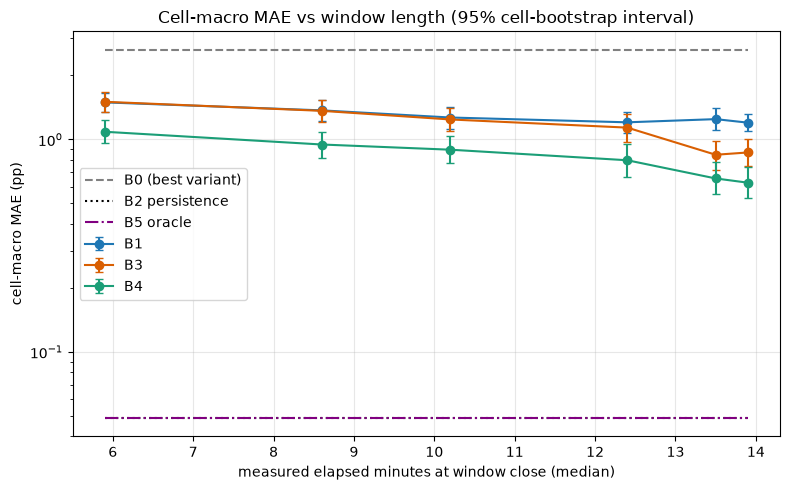

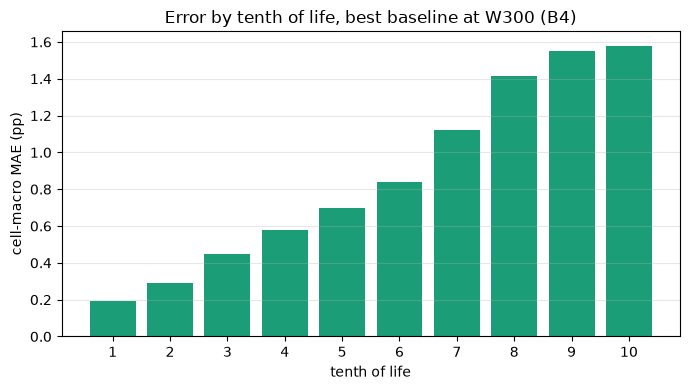

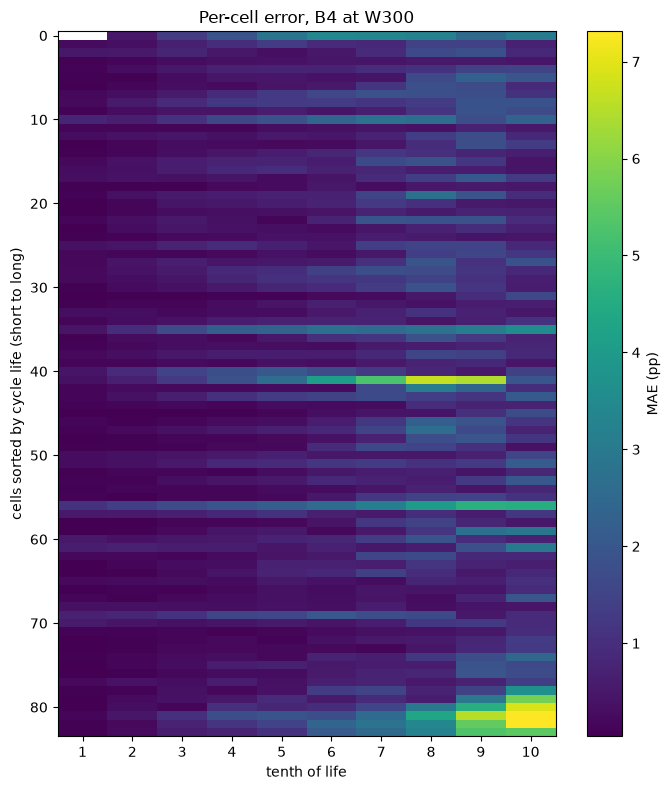

In [16]:
# Figures
cols = {"B1": "#1f77b4", "B3": "#d95f02", "B4": "#1b9e77"}
xs = [MINUTES[w] for w in WINDOWS]
fig, ax = plt.subplots(figsize=(8, 5))
for mdl in ("B1", "B3", "B4"):
    est = np.array([CI[(mdl, w)][0] for w in WINDOWS]); lo = np.array([CI[(mdl, w)][1] for w in WINDOWS]); hi = np.array([CI[(mdl, w)][2] for w in WINDOWS])
    ax.errorbar(xs, est, yerr=[est - lo, hi - est], marker="o", capsize=3, color=cols[mdl], label=mdl)
ax.plot(xs, [mean_mae(B0BEST[w], w) for w in WINDOWS], "--", color="gray", label="B0 (best variant)")
ax.plot(xs, [mean_mae("B2", w) for w in WINDOWS], ":", color="black", label="B2 persistence")
ax.plot(xs, [mean_mae("B5", w) for w in WINDOWS], "-.", color="purple", label="B5 oracle")
ax.set_xlabel("measured elapsed minutes at window close (median)"); ax.set_ylabel("cell-macro MAE (pp)")
ax.set_title("Cell-macro MAE vs window length (95% cell-bootstrap interval)"); ax.set_yscale("log"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(wpath(FIG / "mae_vs_minutes.png"), dpi=150); plt.show(); plt.close(fig)

best300 = min(["B0a", "B0b", "B1", "B3", "B4"], key=lambda m_: mean_mae(m_, "W300"))
st = STAGE[(STAGE.model == best300) & (STAGE.window == "W300") & (STAGE.stage.astype(str) != "last20")].copy()
st["stage"] = st["stage"].astype(int); st = st.sort_values("stage")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(st["stage"] + 1, st["cell_macro_mae_pp"], color=cols.get(best300, "#555555"))
ax.set_xlabel("tenth of life"); ax.set_ylabel("cell-macro MAE (pp)"); ax.set_xticks(range(1, 11))
ax.set_title(f"Error by tenth of life, best baseline at W300 ({best300})"); ax.grid(alpha=0.3, axis="y")
fig.tight_layout(); fig.savefig(wpath(FIG / "error_by_life_tenth_W300.png"), dpi=150); plt.show(); plt.close(fig)

order = np.argsort(LIFE); H = np.full((NC, 10), np.nan)
for dcl in range(10):
    for ci_, c in enumerate(order):
        vals = []
        for r in range(NREP):
            rows_ = CELL_ROWS[c]; rows_ = rows_[(DEC[rows_] == dcl) & VALID["W300"][rows_]]
            if len(rows_): vals.append(np.mean(np.abs(PRED[("B4", "W300", r)][rows_] - Y[rows_])) * 100)
        if vals: H[ci_, dcl] = np.mean(vals)
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(H, aspect="auto", cmap="viridis"); fig.colorbar(im, label="MAE (pp)")
ax.set_xlabel("tenth of life"); ax.set_ylabel("cells sorted by cycle life (short to long)"); ax.set_xticks(range(10)); ax.set_xticklabels(range(1, 11))
ax.set_title("Per-cell error, B4 at W300")
fig.tight_layout(); fig.savefig(wpath(FIG / "cell_error_heatmap_B4_W300.png"), dpi=150); plt.show(); plt.close(fig)

## 7. Report

In [17]:
# Final report (verification_report.json, phase4_report.txt) and printed summary
for p_ in [OUT / n_ for n_ in ["baseline_results.csv", "baseline_by_cell.csv", "baseline_by_stage.csv", "baseline_by_batch.csv",
                                "bootstrap_ci.csv", "week2_gate.json", "gate_hash.txt", "model_inputs.csv", "tuning_log.csv"]]:
    check(f"artifact exists: {p_.name}", p_.exists(), "", "WARN")

L = []; A = L.append
A("PHASE 4 REPORT")
A(f"runtime (this session): {(time.time() - T0) / 60:.1f} min | seed {SEED} | boot {BOOT}")
A(f"rows: development scored {n} | cells {NC} (b1 {(BN == 1).sum()}, b2 {(BN == 2).sum()}) | per window "
  + ", ".join(f"{w} {len(SEL[w])}" for w in WINDOWS))
A("")
A("cell-macro MAE in pp, mean +- sd over repeats")
A(f"{'window':7}" + "".join(f"{m_:>13}" for m_ in MODELS))
for win in WINDOWS:
    A(f"{win:7}" + "".join(f"{MEAN.loc[(m_, win), 'mean']:>7.3f}+-{0 if np.isnan(MEAN.loc[(m_, win), 'std']) else MEAN.loc[(m_, win), 'std']:<4.2f}" for m_ in MODELS))
A("")
A("paired differences in cell-macro MAE, pp, estimate [95% cluster-bootstrap interval]")
for win in WINDOWS:
    A(f"{win:6}" + "  ".join(f"{a}-{b} {PAIRED[(a, b, win)][0]:+.3f} [{PAIRED[(a, b, win)][1]:+.3f},{PAIRED[(a, b, win)][2]:+.3f}]"
                             for a, b in [("B3", B0BEST[win]), ("B4", "B3"), ("B1", "B3")]))
A("")
A("canaries")
if CAN_A: A(f"  a. label shuffle W300 r0: B3 {CAN_A.get('B3', float('nan')):.3f}, B4 {CAN_A.get('B4', float('nan')):.3f} pp vs best B0 {CAN_A.get('best_B0', float('nan')):.3f} pp")
for k_, v_ in CAN_B.items(): A(f"  b. tail {k_}: R2 {v_['r2']:.4f}, MAE {v_['mae_pp']:.3f} pp ({v_['rows']} rows)")
for k_, v_ in CAN_C.items(): A(f"  c. scalar {k_}: R2 {v_['r2']:.3f} (Phase 3b {v_['phase3b_r2']}), MAE {v_['mae_pp']:.3f} pp")
A("")
A(f"gate (M1 target = {1 - GATE_IMPROVEMENT:.2f} x best baseline), pp")
for win in WINDOWS:
    t_ = TARGETS[win]; A(f"  {win}: best {t_['best_baseline']} {t_['best_cell_macro_mae_pp']:.3f} -> target {t_['m1_target_pp']:.3f} | B2 {t_['B2_pp']:.3f} | B5 {t_['B5_pp']:.3f}")
A("within 15% of B2: " + ("; ".join(WITHIN15) if WITHIN15 else "none"))
A("B3 vs B4 (does the waveform add anything?):")
for s_ in B3B4: A("  " + s_)
A("")
cm = CELLMAE[(best300, "W300")]; w5 = np.argsort(-cm)[:5]
A(f"five worst cells, best baseline at W300 ({best300}):")
for c in w5: A(f"  {dev_cells[c]:8} MAE {cm[c]:.3f} pp | life {LIFE[c]:.0f} | batch {BN[c]}")
A("")
for stt in ("PASS", "WARN", "FAIL"):
    items = [c for c in CHECKS if c["status"] == stt]
    A(f"{stt} ({len(items)})")
    for c in items:
        if stt != "PASS" or len(items) <= 25: A(f"  - {c['name']}" + (f" | {c['detail']}" if c["detail"] else ""))
A(f"errors recorded ({len(ERRORS)})")
for e in ERRORS: A(f"  - {e['where']}: {e['error']}")
A("")
A("artifacts")
for p_ in sorted(list(OUT.glob("*")) + list(FIG.glob("*"))):
    if p_.is_file(): A(f"  {p_.relative_to(OUT)} {p_.stat().st_size / 1024:.1f} KB")
cf = [p_ for p_ in CACHE.glob("*") if p_.is_file()]
A(f"  cache/ {len(cf)} files {sum(p_.stat().st_size for p_ in cf) / 1024**2:.1f} MB")

report_txt = "\n".join(L)
(OUT / "phase4_report.txt").write_text(report_txt)
ver = {"runtime_min": (time.time() - T0) / 60, "checks": CHECKS, "errors": ERRORS,
       "counts": {s_: sum(c["status"] == s_ for c in CHECKS) for s_ in ("PASS", "WARN", "FAIL")},
       "row_counts": gate["row_counts"], "gate_sha256": gate_hash}
(OUT / "verification_report.json").write_text(json.dumps(ver, indent=2))
print(report_txt)

[PASS] artifact exists: baseline_results.csv
[PASS] artifact exists: baseline_by_cell.csv
[PASS] artifact exists: baseline_by_stage.csv
[PASS] artifact exists: baseline_by_batch.csv
[PASS] artifact exists: bootstrap_ci.csv
[PASS] artifact exists: week2_gate.json
[PASS] artifact exists: gate_hash.txt
[PASS] artifact exists: model_inputs.csv
[PASS] artifact exists: tuning_log.csv
PHASE 4 REPORT
runtime (this session): 48.0 min | seed 42 | boot 5000
rows: development scored 55963 | cells 84 (b1 41, b2 43) | per window W310 55963, W305 55963, W300 55963, W280 55963, W240 55963, WFULL 55963

cell-macro MAE in pp, mean +- sd over repeats
window           B0a          B0b           B1           B2           B3           B4           B5
W310     2.737+-0.01  2.644+-0.01  1.495+-0.00  0.049+-0.00  1.504+-0.01  1.087+-0.01  0.049+-0.00
W305     2.737+-0.01  2.644+-0.01  1.370+-0.00  0.049+-0.00  1.363+-0.01  0.947+-0.01  0.049+-0.00
W300     2.737+-0.01  2.644+-0.01  1.268+-0.00  0.049+-0.00  1.